# Imports

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

# Part (a)

In [ ]:
file_path = "/content/ecoli.csv"
df = pd.read_csv(
    file_path,
    sep=",",
    header=None
)
print(df.head())

      0     1     2    3     4     5     6   7
0  0.49  0.29  0.48  0.5  0.56  0.24  0.35  cp
1  0.07  0.40  0.48  0.5  0.54  0.35  0.44  cp
2  0.56  0.40  0.48  0.5  0.49  0.37  0.46  cp
3  0.59  0.49  0.48  0.5  0.52  0.45  0.36  cp
4  0.23  0.32  0.48  0.5  0.55  0.25  0.35  cp


In [ ]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (336, 8)

First 5 rows:
      0     1     2    3     4     5     6   7
0  0.49  0.29  0.48  0.5  0.56  0.24  0.35  cp
1  0.07  0.40  0.48  0.5  0.54  0.35  0.44  cp
2  0.56  0.40  0.48  0.5  0.49  0.37  0.46  cp
3  0.59  0.49  0.48  0.5  0.52  0.45  0.36  cp
4  0.23  0.32  0.48  0.5  0.55  0.25  0.35  cp

Data types:
0    float64
1    float64
2    float64
3    float64
4    float64
5    float64
6    float64
7     object
dtype: object

Missing values:
0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
dtype: int64


In [ ]:
n_columns = df.shape[1]

X = df.iloc[:, 0:7].to_numpy(dtype=float)
y = df.iloc[:, 7].to_numpy()

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)


Feature matrix shape: (336, 7)
Labels shape: (336,)


In [ ]:
unique_classes, class_counts = np.unique(y, return_counts=True)

for class_name, count in zip(unique_classes, class_counts):
    print(class_name, ":", count)

print("\nTotal samples:", len(y))
print("Number of classes:", len(unique_classes))


cp : 143
im : 77
imL : 2
imS : 2
imU : 35
om : 20
omL : 5
pp : 52

Total samples: 336
Number of classes: 8


In [ ]:
selected_classes = ["cp", "im", "pp", "imU", "om"]
mask = np.isin(y, selected_classes)

X_filtered = X[mask]
y_filtered = y[mask]

print("Original dataset size:", len(y))
print("Filtered dataset size:", len(y_filtered))

print("\nClass distribution after filtering:")

for class_name in selected_classes:
    count = np.sum(y_filtered == class_name)
    print(class_name, ":", count)


Original dataset size: 336
Filtered dataset size: 327

Class distribution after filtering:
cp : 143
im : 77
pp : 52
imU : 35
om : 20


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;">انتخاب کلاس‌ها</h3>

<p>طبق صورت سؤال، فقط کلاس‌هایی را نگه می‌داریم که حداقل ۲۰ نمونه داشته باشند.</p>

<p>بنابراین کلاس‌های cp، im، pp، imU و om انتخاب شده‌اند و کلاس‌های imL، imS و omL به دلیل تعداد نمونه‌های کم حذف می‌شوند.</p>

<p>بعد از این مرحله، از مجموع 336 نمونه اولیه، 327 نمونه باقی می‌ماند. توزیع نمونه‌ها در کلاس‌های انتخاب‌شده به شکل زیر است:</p>

<div dir="ltr" style="text-align: left; background: #f1f5f9; padding: 12px; border-radius: 8px; margin: 12px 0;">
  <p>cp: 143 samples</p>
  <p>im: 77 samples</p>
  <p>pp: 52 samples</p>
  <p>imU: 35 samples</p>
  <p>om: 20 samples</p>
</div>

</div>

In [ ]:
rng = np.random.default_rng(0)

train_indices = []
test_indices = []

for class_name in selected_classes:

    class_indices = np.where(y_filtered == class_name)[0]
    shuffled_indices = rng.permutation(class_indices)
    n_train = round(0.7 * len(class_indices))

    # Split indices
    train_indices.extend(shuffled_indices[:n_train])
    test_indices.extend(shuffled_indices[n_train:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X_filtered[train_indices]
X_test = X_filtered[test_indices]

y_train = y_filtered[train_indices]
y_test = y_filtered[test_indices]

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))


Training samples: 228
Test samples: 99


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;">تقسیم داده‌ها به مجموعه‌های آموزش و آزمون</h3>

<p>برای اینکه تقسیم داده‌ها قابل تکرار باشد، از Random Generator با Seed برابر صفر استفاده کرده‌ایم.</p>

<p>این تقسیم‌بندی به صورت جداگانه برای هر کلاس انجام می‌شود. ابتدا اندیس نمونه‌های هر کلاس با استفاده از <code>rng.permutation</code> به‌صورت تصادفی جابه‌جا شده و سپس اولین <code>round(0.7 * n_k)</code> نمونه به مجموعه آموزش و باقی نمونه‌ها به مجموعه آزمون اختصاص داده می‌شوند.</p>

<p>در نهایت، 228 نمونه برای آموزش و 99 نمونه برای آزمون خواهیم داشت. از آنجا که تقسیم‌بندی برای هر کلاس به‌صورت مستقل انجام شده، نسبت تقریبی 70/30 در هر پنج کلاس حفظ می‌شود.</p>

</div>

In [ ]:
print("Class distribution in Training set:")
for class_name in selected_classes:
    count = np.sum(y_train == class_name)
    print(class_name, ":", count)

print("\nClass distribution in Test set:")
for class_name in selected_classes:
    count = np.sum(y_test == class_name)
    print(class_name, ":", count)


Class distribution in Training set:
cp : 100
im : 54
pp : 36
imU : 24
om : 14

Class distribution in Test set:
cp : 43
im : 23
pp : 16
imU : 11
om : 6


In [ ]:
n_samples, n_features = X_train.shape

classes = selected_classes
n_classes = len(classes)

print("Number of training samples:", n_samples)
print("Number of features:", n_features)
print("Number of classes:", n_classes)
print("Classes:", classes)

Number of training samples: 228
Number of features: 7
Number of classes: 5
Classes: ['cp', 'im', 'pp', 'imU', 'om']


In [ ]:

class_priors = np.zeros(n_classes)
for i, class_name in enumerate(classes):
    n_class_samples = np.sum(y_train == class_name)
    class_priors[i] = n_class_samples / n_samples

    print(
        class_name,
        "Count:", n_class_samples,
        "Prior:", class_priors[i]
    )

print("\nSum of priors:", np.sum(class_priors))

cp Count: 100 Prior: 0.43859649122807015
im Count: 54 Prior: 0.23684210526315788
pp Count: 36 Prior: 0.15789473684210525
imU Count: 24 Prior: 0.10526315789473684
om Count: 14 Prior: 0.06140350877192982

Sum of priors: 0.9999999999999999


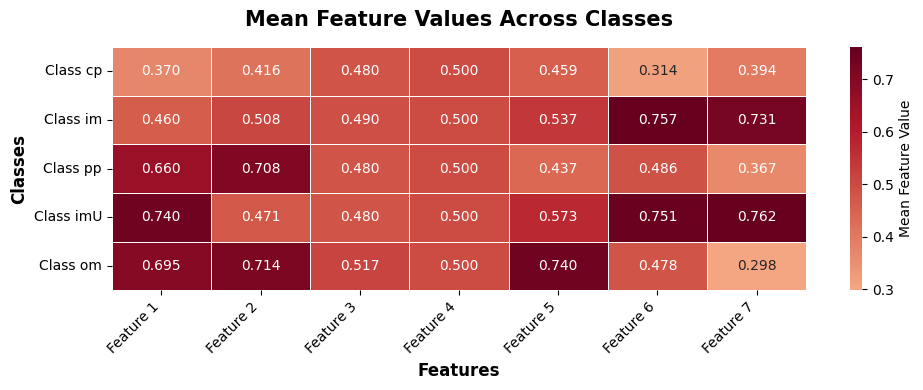

Class Means Shape: (5, 7)

Class Means Summary:
           Feature 1  Feature 2  Feature 3  Feature 4  Feature 5  Feature 6  Feature 7
Class cp      0.3705     0.4156     0.4800        0.5     0.4591     0.3142     0.3941
Class im      0.4598     0.5081     0.4896        0.5     0.5372     0.7572     0.7309
Class pp      0.6597     0.7075     0.4800        0.5     0.4372     0.4856     0.3672
Class imU     0.7396     0.4708     0.4800        0.5     0.5725     0.7512     0.7621
Class om      0.6950     0.7136     0.5171        0.5     0.7400     0.4779     0.2979


In [ ]:
class_means = np.zeros((n_classes, n_features))

for i, class_name in enumerate(classes):
    X_class = X_train[y_train == class_name]
    class_means[i] = np.mean(X_class, axis=0)

feature_labels = [f'Feature {i+1}' for i in range(n_features)]

means_df = pd.DataFrame(
    class_means,
    index=[f'Class {c}' for c in classes],
    columns=feature_labels
)

plt.figure(figsize=(max(10, n_features * 0.45), 4))

sns.heatmap(
    means_df,
    annot=n_features <= 15,
    fmt='.3f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Mean Feature Value'}
)

plt.title('Mean Feature Values Across Classes',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Features', fontsize=12, fontweight='bold')
plt.ylabel('Classes', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("Class Means Shape:", class_means.shape)
print("\nClass Means Summary:")
print(means_df.round(4).to_string())

In [ ]:
class_variances = np.zeros((n_classes, n_features))

for i, class_name in enumerate(classes):
    X_class = X_train[y_train == class_name]

    class_variances[i] = np.var(
        X_class,
        axis=0,
        ddof=0
    )

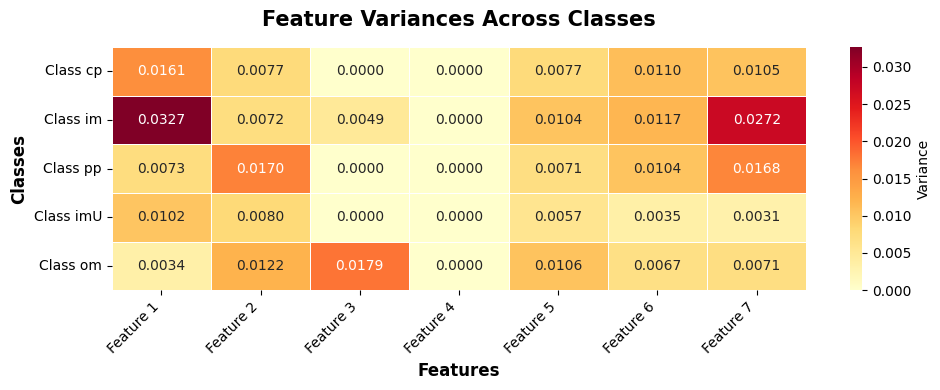

Variances Shape: (5, 7)


In [ ]:
# Create feature labels
feature_labels = [f'Feature {i+1}' for i in range(n_features)]

# Create DataFrame
variances_df = pd.DataFrame(
    class_variances,
    index=[f'Class {c}' for c in classes],
    columns=feature_labels
)

# Plot heatmap
plt.figure(figsize=(max(10, n_features * 0.45), 4))

sns.heatmap(
    variances_df,
    annot=n_features <= 15,
    fmt='.4f',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Variance'}
)

plt.title('Feature Variances Across Classes',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Features', fontsize=12, fontweight='bold')
plt.ylabel('Classes', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("Variances Shape:", class_variances.shape)

<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;">محاسبه پارامترهای مدل</h3>

<p>برای پیاده‌سازی Gaussian Naive Bayes، ابتدا پارامترهای مورد نیاز را با استفاده از داده‌های مجموعه آموزش محاسبه می‌کنیم.</p>

<p>برای هر کلاس، سه پارامتر زیر مورد نیاز است:</p>

<p>1. <strong>Class Prior:</strong> احتمال اولیه تعلق یک نمونه به کلاس مورد نظر که از نسبت تعداد نمونه‌های آن کلاس به کل نمونه‌های آموزش محاسبه می‌شود.</p>

<p>2. <strong>Class Mean:</strong> میانگین هر ویژگی برای نمونه‌هایی که به کلاس مورد نظر تعلق دارند.</p>

<p>3. <strong>Class Variance:</strong> واریانس هر ویژگی برای نمونه‌های هر کلاس.</p>

<p>از آنجا که تنها از مجموعه آموزش برای محاسبه این مقادیر استفاده می‌کنیم، اطلاعات مجموعه آزمون در تخمین پارامترهای مدل دخالتی ندارد.</p>

<p>برای محاسبه واریانس نیز از <code>ddof=0</code> استفاده شده است که مطابق برآورد Maximum Likelihood برای توزیع Gaussian است.</p>

</div>

In [ ]:
zero_variance_mask = class_variances < 1e-12
n_zero_variances = np.sum(zero_variance_mask)
print("Number of zero variances:", n_zero_variances)

print("\nClass-feature pairs with zero variance:")
for i, class_name in enumerate(classes):
    for j in range(n_features):
        if zero_variance_mask[i, j]:
            print(
                "Class:", class_name,
                "| Feature:", j + 1,
                "| Variance:", class_variances[i, j]
            )

Number of zero variances: 8

Class-feature pairs with zero variance:
Class: cp | Feature: 3 | Variance: 6.039716305598372e-31
Class: cp | Feature: 4 | Variance: 0.0
Class: im | Feature: 4 | Variance: 0.0
Class: pp | Feature: 3 | Variance: 1.1093356479670479e-31
Class: pp | Feature: 4 | Variance: 0.0
Class: imU | Feature: 3 | Variance: 7.703719777548943e-32
Class: imU | Feature: 4 | Variance: 0.0
Class: om | Feature: 4 | Variance: 0.0


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>طبق خروجی محاسبات، تعداد 8 زوج (Class, Feature) دارای واریانس کمتر از مقدار 10^-12 هستند.</p>

<p>بخش زیادی از این مقادیر مربوط به Feature 4 است که در تمام کلاس‌ها تقریباً مقدار ثابتی برابر با 0.5 دارد. همچنین Feature 3 در بعضی از کلاس‌ها تقریباً ثابت است.</p>

<p>مقادیر بسیار کوچک به جای صفر دقیق نیز به دلیل محدودیت دقت محاسبات اعشاری کامپیوتر ایجاد شده‌اند.</p>

</div>

In [ ]:
variance_floor = 1e-4
class_variances_floored = np.maximum(
    class_variances,
    variance_floor
)

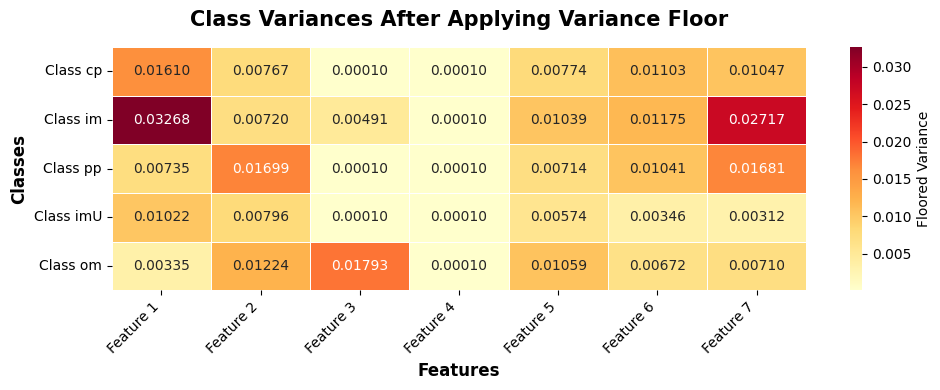

Floored Variances Shape: (5, 7)


In [ ]:
# Create feature labels
feature_labels = [f'Feature {i+1}' for i in range(n_features)]

# Create DataFrame
floored_variances_df = pd.DataFrame(
    class_variances_floored,
    index=[f'Class {c}' for c in classes],
    columns=feature_labels
)

# Plot heatmap
plt.figure(figsize=(max(10, n_features * 0.45), 4))

sns.heatmap(
    floored_variances_df,
    annot=n_features <= 15,
    fmt='.5f',
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Floored Variance'}
)

plt.title('Class Variances After Applying Variance Floor',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Features', fontsize=12, fontweight='bold')
plt.ylabel('Classes', fontsize=12, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("Floored Variances Shape:", class_variances_floored.shape)


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;"> آیا Variance Floor کافی است؟</h3>


<p> خیر، لزوماً کافی نیست.</p>

<p>بطور مثال ممکن است دو ویژگی با واریانس‌های زیر را داشته باشیم  :</p>

<div dir="ltr" style="text-align: center; background: #f1f5f9; padding: 12px; border-radius: 8px; margin: 12px 0;">
  <p>σ₁² = 0.0001</p>
  <p>σ₂² = 0.05</p>
</div>

<p>ویژگی اول پراکندگی بسیار کمی دارد. در نتیجه، مدل نسبت به اختلاف مقدار مشاهده‌شده با میانگین آن بسیار حساس خواهد بود. در مدل Gaussian Naive Bayes، واریانس کوچک می‌تواند باعث شود اختلاف‌های نسبتاً کوچک در مقدار یک ویژگی، تأثیر بسیار زیادی بر احتمال محاسبه‌شده داشته باشند.</p>

<p>حتی با اعمال Variance Floor، این ویژگی ممکن است همچنان سهم بسیار بزرگی در محاسبه احتمال داشته باشد؛ زیرا Floor صرفاً یک حداقل برای واریانس تعیین می‌کند و لزوماً اختلاف مقیاس بین ویژگی‌ها را برطرف نمی‌کند.</p>

<p>پس  Variance Floor از مشکلات عددی ناشی از واریانس صفر یا بسیار کوچک جلوگیری می‌کند، اما تضمین نمی‌کند که همه ویژگی‌ها تأثیر متعادلی بر تصمیم نهایی مدل داشته باشند.</p>

</div>


In [ ]:
def log_gaussian_probability(X, means, variances):
    """
    Calculating the Log Gaussian Probability for all samples,
    classes, and features
    """

    log_prob = -0.5 * (
        np.log(2 * np.pi)
        + np.log(variances)
        + ((X[:, None, :] - means[None, :, :]) ** 2) / variances[None, :, :]
    )

    return log_prob

In [ ]:
log_probs = log_gaussian_probability(
    X_test,
    class_means,
    class_variances_floored
)

print("Log probabilities shape:", log_probs.shape)
print("\nLog probabilities for first sample:")
print(log_probs[0])


Log probabilities shape: (99, 5, 7)

Log probabilities for first sample:
[[  0.69458774   1.50050224   3.68623165   3.68623165   1.50417834
    1.32320873   1.32854936]
 [  0.11800051   0.73584718   1.72939206   3.68623165   1.14704505
   -6.463937    -0.89530265]
 [ -9.88653863  -1.66394581   3.68623165   3.68623165   1.47670998
    0.20120467   1.04112589]
 [-10.3531162    1.18261855   3.68623165   3.68623165   0.74630189
  -23.72217376 -16.75915161]
 [-27.59456797  -2.73483477   1.05310905   3.68623165  -2.08813342
   -0.04475277   0.50446427]]


In [ ]:
# Sum of Log Gaussian Probabilities over all features
log_likelihood = np.sum(log_probs, axis=2)

# Add Log Prior to each class
log_joint = log_likelihood + np.log(class_priors)

print("Log likelihood shape:", log_likelihood.shape)
print("Log joint shape:", log_joint.shape)

print("\nLog joint scores for first test sample:")
print(log_joint[0])

Log likelihood shape: (99, 5)
Log joint shape: (99, 5)

Log joint scores for first test sample:
[ 12.89931428  -1.38308477  -3.30480728 -43.78434963 -30.00877226]


In [ ]:
def logsumexp(a, axis=None, keepdims=False):
    m = np.max(a, axis=axis, keepdims=True)

    result = m + np.log(
        np.sum(np.exp(a - m), axis=axis, keepdims=True)
    )

    if not keepdims and axis is not None:
        result = np.squeeze(result, axis=axis)

    return result

In [ ]:
# Calculation of the log of the normalization constant
log_normalizer = logsumexp(
    log_joint,
    axis=1,
    keepdims=True
)

# Calculating the Log Posterior
log_posterior = log_joint - log_normalizer

# Converting Log Posterior to Standard Posterior
posterior = np.exp(log_posterior)

print("Posterior shape:", posterior.shape)

print("\nPosterior probabilities for first test sample:")
print(posterior[0])

print("\nSum of posterior probabilities:")
print(np.sum(posterior, axis=1)[:10])


Posterior shape: (99, 5)

Posterior probabilities for first test sample:
[9.99999281e-01 6.26949546e-07 9.17569796e-08 2.41322179e-25
 2.31875292e-19]

Sum of posterior probabilities:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
predicted_class_indices = np.argmax(posterior, axis=1)
y_pred = np.array(classes)[predicted_class_indices]

accuracy = np.mean(y_pred == y_test)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 true labels:")
print(y_test[:10])

print("\nGaussian Naive Bayes Accuracy:")
print(accuracy)

print("Accuracy (%):", accuracy * 100)

First 10 predictions:
['cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp']

First 10 true labels:
['cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp']

Gaussian Naive Bayes Accuracy:
0.8181818181818182
Accuracy (%): 81.81818181818183


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>در مدل Gaussian Naive Bayes فرض می‌کنیم ویژگی‌ها با شرط معلوم بودن کلاس، مستقل از یکدیگر هستند. بنابراین احتمال تعلق یک نمونه به یک کلاس از حاصل‌ضرب احتمال ویژگی‌های آن به دست می‌آید.</p>

<p>برای جلوگیری از مشکلات عددی ناشی از ضرب تعداد زیادی احتمال کوچک، به جای محاسبه مستقیم حاصل‌ضرب، از مجموع لگاریتم احتمال‌ها استفاده می‌کنیم.</p>

<p>در مرحله بعد، Log Prior به Log Likelihood اضافه می‌شود تا امتیاز نهایی هر کلاس به دست آید.</p>

<p>برای محاسبه Posterior نیز از رابطه Log-Sum-Exp استفاده می‌کنیم. در پیاده‌سازی این تابع، ابتدا بیشترین مقدار از امتیازها کم می‌شود تا از Overflow هنگام محاسبه Exponential جلوگیری شود.</p>

<p>در نهایت، با نرمال‌سازی احتمال‌ها، مجموع Posteriorهای هر نمونه برابر یک خواهد بود.</p>

</div>

In [ ]:
variance_floors = [1e-6, 1e-4, 1e-2]
results = []

for floor in variance_floors:
    variances = np.maximum(class_variances, floor)

    # Compute log Gaussian probabilities
    log_probs = log_gaussian_probability(
        X_test,
        class_means,
        variances
    )

    # Sum log probabilities across all features
    log_likelihood = np.sum(log_probs, axis=2)

    # Add log prior probabilities
    log_joint = log_likelihood + np.log(class_priors)

    # Compute log posterior probabilities using the Log-Sum-Exp trick
    log_normalizer = logsumexp(
        log_joint,
        axis=1,
        keepdims=True
    )

    log_posterior = log_joint - log_normalizer

    # Convert log posterior probabilities back to posterior probabilities
    posterior = np.exp(log_posterior)

    # Predict class labels based on the highest posterior probability
    predicted_indices = np.argmax(posterior, axis=1)
    predictions = np.array(classes)[predicted_indices]

    accuracy = np.mean(predictions == y_test)

    results.append({
        "Variance Floor": floor,
        "Accuracy (%)": accuracy * 100
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 Variance Floor  Accuracy (%)
       0.000001     73.737374
       0.000100     81.818182
       0.010000     84.848485


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>برای بررسی تأثیر Variance Floor، مدل را با سه مقدار 10^-6، 10^-4 و 10^-2 ارزیابی کردم.</p>

<p>نتایج نشان می‌دهند که با افزایش مقدار Variance Floor، دقت مدل در این تقسیم‌بندی افزایش پیدا کرده است.</p>

<p>در مقدار 10^-6، دقت مدل برابر 73.74% است. با افزایش Floor به 10^-4، دقت به 81.82% می‌رسد و در نهایت با مقدار 10^-2، بهترین نتیجه یعنی 84.85% به دست می‌آید.</p>

<p>با توجه به نتایج بالا می توان نشان داد انتخاب یک حداقل مناسب برای واریانس‌ها می‌تواند تأثیر قابل توجهی بر عملکرد Gaussian Naive Bayes داشته باشد.</p>

<p>در ادامه، برای محاسبه معیارهای ارزیابی از مقدار 10^-4 استفاده شده که مقدار اصلی در پیاده‌سازی درخواستی سؤال است.</p>

</div>

# Part (b)

In [ ]:
variance_floor = 1e-4
variances = np.maximum(class_variances, variance_floor)

log_probs_b = log_gaussian_probability(
    X_test,
    class_means,
    variances
)

log_likelihood_b = np.sum(log_probs_b, axis=2)
log_joint_b = log_likelihood_b + np.log(class_priors)

log_normalizer_b = logsumexp(
    log_joint_b,
    axis=1,
    keepdims=True
)

log_posterior_b = log_joint_b - log_normalizer_b

posterior_b = np.exp(log_posterior_b)

predicted_indices_b = np.argmax(posterior_b, axis=1)
y_pred_b = np.array(classes)[predicted_indices_b]

print("Accuracy:", np.mean(y_pred_b == y_test))
print("Accuracy (%):", np.mean(y_pred_b == y_test) * 100)

Accuracy: 0.8181818181818182
Accuracy (%): 81.81818181818183


In [ ]:
class_labels = classes

confusion_matrix = np.zeros(
    (len(class_labels), len(class_labels)),
    dtype=int
)
class_to_index = {
    class_name: i
    for i, class_name in enumerate(class_labels)
}

for true_label, predicted_label in zip(y_test, y_pred_b):

    true_index = class_to_index[true_label]
    predicted_index = class_to_index[predicted_label]

    confusion_matrix[predicted_index, true_index] += 1

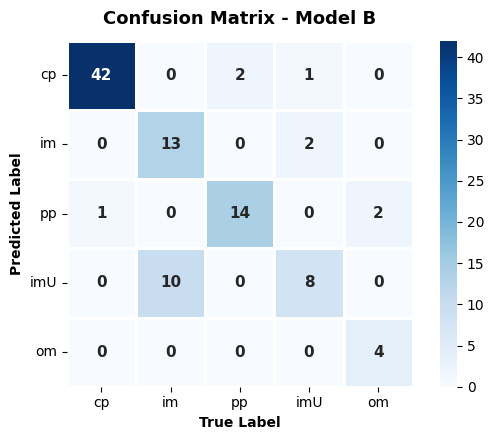

In [ ]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    confusion_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    square=True,
    cbar=True,
    annot_kws={"size": 11, "weight": "bold"},
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title('Confusion Matrix - Model B', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('True Label', fontsize=10, fontweight='bold')
plt.ylabel('Predicted Label', fontsize=10, fontweight='bold')

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>در این ماتریس، مقادیر روی قطر اصلی نشان‌دهنده نمونه‌هایی هستند که به‌درستی طبقه‌بندی شده‌اند.</p>

<p>از مجموع 99 نمونه آزمون، 81 نمونه به‌درستی تشخیص داده شده‌اند که با Accuracy برابر 81.82% مطابقت دارد.</p>

<p>یکی از مهم‌ترین خطاهای مدل مربوط به دو کلاس im و imU است. از 23 نمونه واقعی کلاس im، تعداد 10 نمونه به اشتباه در کلاس imU قرار گرفته‌اند.</p>

<p>همچنین بخشی از نمونه‌های کلاس pp و om نیز به اشتباه در کلاس‌های دیگر طبقه‌بندی شده‌اند.</p>

<p>با توجه به ماتریس بالا، می توان دید که با وجود دقت کلی مناسب، مدل در تشخیص بعضی از کلاس‌ها عملکرد یکسانی ندارد.</p>

</div>

In [ ]:
per_class_metrics = []

for i, class_name in enumerate(class_labels):
    TP = confusion_matrix[i, i]
    FP = np.sum(confusion_matrix[i, :]) - TP
    FN = np.sum(confusion_matrix[:, i]) - TP

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    per_class_metrics.append({
        "Class": class_name,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

metrics_df = pd.DataFrame(per_class_metrics)
print(metrics_df.to_string(index=False))

Class  TP  FP  FN  Precision   Recall  F1-score
   cp  42   3   1   0.933333 0.976744  0.954545
   im  13   2  10   0.866667 0.565217  0.684211
   pp  14   3   2   0.823529 0.875000  0.848485
  imU   8  10   3   0.444444 0.727273  0.551724
   om   4   0   2   1.000000 0.666667  0.800000


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>با بررسی نتایج هر کلاس می‌توان دید که بهترین عملکرد مربوط به کلاس cp است که مقدار F1 آن برابر 0.9545 است.</p>

<p>در مقابل، کلاس imU با مقدار F1 برابر 0.5517 ضعیف‌ترین عملکرد را دارد. دلیل اصلی آن پایین بودن Precision است؛ یعنی تعداد قابل توجهی از نمونه‌هایی که به اشتباه به عنوان imU پیش‌بینی شده‌اند، در واقع متعلق به کلاس im بوده‌اند.</p>

<p>از طرف دیگر، Recall کلاس im نیز نسبتا پایین است. این موضوع با Confusion Matrix مطابقت دارد؛ زیرا تعداد زیادی از نمونه‌های واقعی im به اشتباه در کلاس imU قرار گرفته‌اند.</p>

<p>بنابراین، بنظرم مهم‌ترین چالش مدل در این داده‌ها تشخیص صحیح مرز بین دو کلاس im و imU است.</p>

</div>

In [ ]:
macro_f1 = metrics_df["F1-score"].mean()
print("Macro-F1 (%):", macro_f1 * 100)

Macro-F1 (%): 76.77929934554253


In [ ]:
total_TP = metrics_df["TP"].sum()
total_FP = metrics_df["FP"].sum()
total_FN = metrics_df["FN"].sum()

micro_precision = total_TP / (total_TP + total_FP)
micro_recall = total_TP / (total_TP + total_FN)

micro_f1 = (
    2 * micro_precision * micro_recall
    / (micro_precision + micro_recall)
)

print("Micro Precision:", micro_precision)
print("Micro Recall:", micro_recall)
print("Micro F1:", micro_f1)

Micro Precision: 0.8181818181818182
Micro Recall: 0.8181818181818182
Micro F1: 0.8181818181818182



<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;"> چرا Micro-F1 برابر Accuracy می شود؟</h3>



<p>میدانیم در این مسئله هر نمونه به یک کلاس متعلق است و پیش بینی کننده ما نیز یک کلاس برای هر نمونه مشخص می کند. پس هر بار که پیش بینی اشتباهی انجام می دهیم، دقیقا یک واحد به FN برای کلاس واقعی آن نمونه ایجاد می شود و همچنین دقیقا یک واحد FP برای کلاس اشتباهی که ما پیش بینی کرده ایم.
 پس خواهیم داشت:</p>

<div dir="ltr" style="text-align: center; background: #f1f5f9; padding: 12px; border-radius: 8px; margin: 12px 0;">
  <p>&Sigma;FP = &Sigma;FN</p>
  <p>Micro-Precision = &Sigma;TP / &Sigma;TP +&Sigma;FP</p>
  <p>Micro-Recall = &Sigma;TP / &Sigma;TP +&Sigma;FN</p>
  N = &Sigma;TP + &Sigma;FP = &Sigma;TP + &Sigma;FN
  &rarr;
  Micro-Precision + Micro-Recall =  &Sigma; =TP / N = Accuracy
</div>



<p>نشان دادیم که در این حالت Micro-Precision , Micro-Recall برابر Accuracy خواهند بود، اکنون اگر آنها را در فرمول مربوط به محاسبه Micro-F1 قرار دهیم، چون برابر هستند باز هم برابر Accuracy خواهند بود.</p>

In [ ]:
class_supports = np.sum(confusion_matrix, axis=0)
weighted_f1 = np.sum(
    metrics_df["F1-score"].to_numpy() * class_supports
) / np.sum(class_supports)

print("Class supports:")
print(dict(zip(class_labels, class_supports)))

print("\nWeighted-F1:", weighted_f1)
print("Weighted-F1 (%):", weighted_f1 * 100)


Class supports:
{'cp': np.int64(43), 'im': np.int64(23), 'pp': np.int64(16), 'imU': np.int64(11), 'om': np.int64(6)}

Weighted-F1: 0.8204749469062288
Weighted-F1 (%): 82.04749469062288


In [ ]:
summary_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro-F1",
        "Micro-F1",
        "Weighted-F1"
    ],
    "Score": [
        np.mean(y_pred_b == y_test),
        macro_f1,
        micro_f1,
        weighted_f1
    ]
})

summary_metrics["Score (%)"] = summary_metrics["Score"] * 100

styled_summary = (
    summary_metrics.style
    .format({
        "Score": "{:.4f}",
        "Score (%)": "{:.2f}%"
    })
    .background_gradient(
        subset=["Score (%)"],
        cmap="YlGn"
    )
    .set_caption("Gaussian Naive Bayes Performance Summary")
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("color", "#2C3E50")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#1F4E79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("padding", "8px")
            ]
        }
    ])
)

styled_summary

,Metric,Score,Score (%)
0,Accuracy,0.8182,81.82%
1,Macro-F1,0.7678,76.78%
2,Micro-F1,0.8182,81.82%
3,Weighted-F1,0.8205,82.05%


# Part (c)

In [ ]:
# Store the full covariance matrix for each class
class_covariances = np.zeros(
    (n_classes, n_features, n_features)
)

for i, class_name in enumerate(classes):

    X_class = X_train[y_train == class_name]

    class_mean = np.mean(X_class, axis=0)
    X_centered = X_class - class_mean

    # Calculate the full covariance matrix using MLE
    class_covariances[i] = (
        X_centered.T @ X_centered
    ) / len(X_class)

In [ ]:
print("Covariance Matrices Shape:", class_covariances.shape)
for i, class_name in enumerate(classes):
    covariance_df = pd.DataFrame(
        class_covariances[i],
        columns=[f"F{j+1}" for j in range(class_covariances.shape[1])],
        index=[f"F{j+1}" for j in range(class_covariances.shape[1])]
    )

    display(
        covariance_df.style
        .format("{:.4f}")
        .background_gradient(cmap="Blues")
        .set_caption(f"Covariance Matrix ({class_name})")
    )

Covariance Matrices Shape: (5, 7, 7)


,F1,F2,F3,F4,F5,F6,F7
F1,0.0161,0.0025,0.0000,0.0000,-0.0001,-0.0000,-0.0014
F2,0.0025,0.0077,0.0000,0.0000,-0.0026,0.0023,0.0013
F3,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000
F4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
F5,-0.0001,-0.0026,-0.0000,0.0000,0.0077,-0.0013,-0.0007
F6,-0.0000,0.0023,0.0000,0.0000,-0.0013,0.0110,0.0096
F7,-0.0014,0.0013,-0.0000,0.0000,-0.0007,0.0096,0.0105


,F1,F2,F3,F4,F5,F6,F7
F1,0.0327,0.0036,0.0013,0.0000,0.0076,0.0026,0.0119
F2,0.0036,0.0072,-0.0001,0.0000,-0.0009,-0.0006,-0.0027
F3,0.0013,-0.0001,0.0049,0.0000,0.0000,0.0001,0.0007
F4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
F5,0.0076,-0.0009,0.0000,0.0000,0.0104,0.0001,0.0050
F6,0.0026,-0.0006,0.0001,0.0000,0.0001,0.0117,0.0105
F7,0.0119,-0.0027,0.0007,0.0000,0.0050,0.0105,0.0272


,F1,F2,F3,F4,F5,F6,F7
F1,0.0073,0.0038,-0.0000,0.0000,-0.0019,0.0030,-0.0016
F2,0.0038,0.0170,0.0000,0.0000,-0.0048,-0.0012,-0.0036
F3,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000
F4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
F5,-0.0019,-0.0048,0.0000,0.0000,0.0071,-0.0009,0.0013
F6,0.0030,-0.0012,-0.0000,0.0000,-0.0009,0.0104,0.0043
F7,-0.0016,-0.0036,0.0000,0.0000,0.0013,0.0043,0.0168


,F1,F2,F3,F4,F5,F6,F7
F1,0.0102,0.0006,-0.0000,0.0000,-0.0026,0.0015,0.0003
F2,0.0006,0.0080,0.0000,0.0000,-0.0007,0.0000,0.0007
F3,-0.0000,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000
F4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
F5,-0.0026,-0.0007,0.0000,0.0000,0.0057,0.0009,0.0023
F6,0.0015,0.0000,-0.0000,0.0000,0.0009,0.0035,0.0026
F7,0.0003,0.0007,-0.0000,0.0000,0.0023,0.0026,0.0031


,F1,F2,F3,F4,F5,F6,F7
F1,0.0034,0.0009,-0.0035,0.0000,0.0027,0.0013,-0.0027
F2,0.0009,0.0122,0.0017,0.0000,-0.0038,0.0042,0.0027
F3,-0.0035,0.0017,0.0179,0.0000,0.0011,0.0042,0.0083
F4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
F5,0.0027,-0.0038,0.0011,0.0000,0.0106,0.0040,-0.0015
F6,0.0013,0.0042,0.0042,0.0000,0.0040,0.0067,0.0012
F7,-0.0027,0.0027,0.0083,0.0000,-0.0015,0.0012,0.0071


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>در Gaussian Naive Bayes فرض می‌کردیم ویژگی‌ها با شرط معلوم بودن کلاس از یکدیگر مستقل هستند. به همین دلیل، فقط واریانس هر ویژگی را به صورت جداگانه در نظر می‌گرفتیم.</p>

<p>اما در QDA این فرض کنار گذاشته می‌شود و وابستگی بین ویژگی‌ها نیز در محاسبات لحاظ می‌شود.</p>

<p>برای هر کلاس، یک ماتریس کوواریانس کامل با ابعاد 7 در 7 محاسبه شده. مقادیر قطر اصلی ماتریس نشان‌دهنده واریانس ویژگی‌ها هستند و سایر مقادیر، کوواریانس بین جفت ویژگی‌ها را نشان می‌دهند.</p>

<p>بنابراین، برخلاف Gaussian Naive Bayes، در این مدل ارتباط بین ویژگی‌ها نیز در محاسبه احتمال و تصمیم‌گیری نهایی تأثیرگذار است.</p>

</div>

In [ ]:
# covariance regularization strength
epsilon = 1e-4
identity_matrix = np.eye(n_features)

regularized_covariances = np.zeros_like(class_covariances)

for i in range(n_classes):
    # Add epsilon times the identity matrix
    regularized_covariances[i] = (
        class_covariances[i]
        + epsilon * identity_matrix
    )

In [ ]:
# Examining the determinant and the smallest eigenvalue of any matrix
for i, class_name in enumerate(classes):

    # Calculate the determinant
    determinant = np.linalg.det(
        regularized_covariances[i]
    )

    # Calculate eigenvalues
    eigenvalues = np.linalg.eigvalsh(
        regularized_covariances[i]
    )

    print(f"\nClass: {class_name}")
    print("Determinant:", determinant)
    print("Minimum eigenvalue:", np.min(eigenvalues))



Class: cp
Determinant: 1.855907354297374e-19
Minimum eigenvalue: 9.999999999999804e-05

Class: im
Determinant: 1.3987077006185848e-16
Minimum eigenvalue: 9.999999999999983e-05

Class: pp
Determinant: 7.893013705673302e-19
Minimum eigenvalue: 9.999999999999831e-05

Class: imU
Determinant: 9.507705474021252e-21
Minimum eigenvalue: 9.999999999999992e-05

Class: om
Determinant: 1.4351069473284184e-18
Minimum eigenvalue: 9.99999999999994e-05


In [ ]:
def log_multivariate_gaussian(X, means, covariances):
    n_samples, n_features = X.shape
    n_classes = means.shape[0]

    # Store log probabilities for all samples and classes
    log_probs = np.zeros((n_samples, n_classes))

    for k in range(n_classes):
        covariance = covariances[k]
        # Calculate the log determinant
        sign, log_determinant = np.linalg.slogdet(covariance)

        if sign <= 0:
            raise ValueError("Covariance matrix must have a positive determinant.")

        for i in range(n_samples):
            # Calculate the difference from the class mean
            difference = X[i] - means[k]
            # Solve the covariance linear system
            solution = np.linalg.solve(covariance, difference)
            # Calculate the squared Mahalanobis distance
            mahalanobis_distance = difference @ solution

            # Calculate the multivariate log Gaussian probability
            log_probs[i, k] = -0.5 * (
                n_features * np.log(2 * np.pi)
                + log_determinant
                + mahalanobis_distance
            )

    return log_probs

In [ ]:
# Calculate multivariate log Gaussian probabilities
qda_log_probs = log_multivariate_gaussian(
    X_test,
    class_means,
    regularized_covariances
)

print("QDA log probabilities shape:")
print(qda_log_probs.shape)

print("\nLog probabilities for the first test sample:")
print(qda_log_probs[0])


QDA log probabilities shape:
(99, 5)

Log probabilities for the first test sample:
[ 14.66244186   2.50033068   1.92837961 -14.8312658  -32.07443202]


In [ ]:
# Add log class priors to the QDA log probabilities
qda_log_joint = qda_log_probs + np.log(class_priors)

In [ ]:
# Calculate the log normalization constant
qda_log_normalizer = logsumexp(
    qda_log_joint,
    axis=1,
    keepdims=True
)

# Calculate log posterior probabilities
qda_log_posterior = qda_log_joint - qda_log_normalizer

# Convert log posterior probabilities to regular probabilities
qda_posterior = np.exp(qda_log_posterior)

print("\nPosterior probabilities for the first test sample:")
print(qda_posterior[0])


Posterior probabilities for the first test sample:
[9.99996117e-01 2.82133269e-06 1.06161696e-06 3.72610484e-14
 7.05602198e-22]


In [ ]:
# Find the class with the highest posterior probability
qda_predicted_indices = np.argmax(
    qda_posterior,
    axis=1
)

# Convert predicted indices to class labels
y_pred_qda = np.array(classes)[qda_predicted_indices]

# Calculate QDA accuracy
qda_accuracy = np.mean(y_pred_qda == y_test)

print("First 10 QDA predictions:")
print(y_pred_qda[:10])

print("\nFirst 10 true labels:")
print(y_test[:10])

print("QDA Accuracy (%):", qda_accuracy * 100)


First 10 QDA predictions:
['cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp']

First 10 true labels:
['cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp' 'cp']
QDA Accuracy (%): 80.8080808080808


In [ ]:
# Gaussian Naive Bayes accuracy
gnb_accuracy = np.mean(y_pred_b == y_test)
# QDA accuracy
qda_accuracy = np.mean(y_pred_qda == y_test)

In [ ]:
comparison_df = pd.DataFrame({
    "Model": [
        "Gaussian Naive Bayes",
        "QDA"
    ],
    "Accuracy (%)": [
        gnb_accuracy * 100,
        qda_accuracy * 100
    ]
})

comparison_df.style \
    .format({
        "Accuracy": "{:.4f}",
        "Accuracy (%)": "{:.2f}%"
    }) \
    .background_gradient(
        subset=["Accuracy (%)"],
        cmap="YlGn"
    ) \
    .highlight_max(
        subset=["Accuracy (%)"],
        color="#90EE90"
    ) \
    .set_caption("Model Performance Comparison") \
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("color", "#2C3E50"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#1F4E79"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("padding", "8px")
            ]
        }
    ])

,Model,Accuracy (%)
0,Gaussian Naive Bayes,81.82%
1,QDA,80.81%


In [ ]:
# Define the number of features and classes
d = n_features
c = n_classes

# Count independent Gaussian Naive Bayes parameters
gnb_parameters = c * (2 * d) + (c - 1)

# Count independent QDA parameters
qda_parameters = (
    c * (d + d * (d + 1) // 2)
    + (c - 1)
)

print("Gaussian Naive Bayes parameters:", gnb_parameters)
print("QDA parameters:", qda_parameters)
print("Additional QDA parameters:", qda_parameters - gnb_parameters)


Gaussian Naive Bayes parameters: 74
QDA parameters: 179
Additional QDA parameters: 105



<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">

<h3 style="color: #2563eb;"> آیا می‌توان برای کلاس‌های imL و imS با فقط دو نمونه QDA ساخت؟</h3>



<p>امکان ساخت مدل QDA قابل اعتماد با تنها دو نمونه برای کلاس‌های imL و imS وجود ندارد. از نظر ریاضی، در یک فضای ویژگی ۷ بعدی، با داشتن دو نمونه، نقطه میانگین دقیقاً در منتصف فاصله آن‌ها قرار می‌گیرد و بردارهای متمرکز حاصل از کسر میانگین از داده‌ها، کاملاً قرینه و وابسته خطی خواهند بود. این امر سبب می‌شود ماتریس داده‌های متمرکز و متعاقباً ماتریس کوواریانس ۷ در ۷ محاسبه‌شده، دارای حداکثر Rank برابر با یک باشند. از آنجا که معکوس‌پذیری یک ماتریس ۷ بعدی نیازمند رتبه کامل یعنی ۷ است، ماتریس کوواریانس حاصل منفرد شده، دترمینان آن صفر می‌شود و معکوس آن که برای محاسبه تابع چگالی احتمال و مرز تصمیم QDA ضروری است، وجود نخواهد داشت. علاوه بر این، از منظر آماری، یک ماتریس کوواریانس ۷ بعدی دارای ۲۸ پارامتر مستقل شامل واریانس‌ها و کوواریانس‌های متقابل است که تخمین آن‌ها با دو نمونه از نظر درجه آزادی کاملاً غیرممکن و فاقد اعتبار آماری است. حتی اگر با افزودن عبارت انتظام‌دهی به قطر اصلی ماتریس، پایداری محاسباتی ایجاد کرده و ماتریس را معکوس‌پذیر کنیم، این اقدام صرفاً یک راهکار عددی برای جلوگیری از خطای تقسیم بر صفر بوده و عدم کفایت آماری داده‌ها برای برآورد ساختار پراکندگی واقعی کلاس را جبران نمی‌کند.</p>


<div dir="rtl" style="text-align: right; font-family: Vazirmatn, Tahoma, sans-serif; line-height: 2;">


<p>در مدل Gaussian Naive Bayes، با استفاده از Variance Floor از مشکلات محاسباتی ناشی از واریانس‌های صفر و بسیار کوچک جلوگیری شد. نتایج نشان دادند که مقدار انتخاب‌شده برای Variance Floor می‌تواند تاثیر قابل توجهی بر دقت مدل داشته باشد.</p>

<p>همچنین با بررسی Confusion Matrix و معیارهای مختلف مشاهده شد که عملکرد مدل در تمام کلاس‌ها یکسان نیست و بیشترین مشکل در تشخیص کلاس‌های im و imU وجود دارد.</p>

<p>در مقایسه با Gaussian Naive Bayes، مدل QDA با وجود در نظر گرفتن کوواریانس بین ویژگی‌ها، دقت بالاتری به دست نیاورد و در عین حال تعداد پارامترهای بیشتری داشت.</p>

<p>بنابراین، در این مورد، Gaussian Naive Bayes با پیچیدگی کمتر، عملکردی کمی بهتر از QDA نشان داد.</p>

</div>